# Detection efficiency and selection bias of a SN Ia survey

A real survey never sees every supernova that exploded in its footprint: faint, distant or poorly sampled events are missed.
In this example we simulate a realistic population of Type Ia supernovae (SNe Ia), observe it with three months of the real
Zwicky Transient Facility (ZTF) observing logs, and measure how the *detected* sample differs from the *true* one.
You will learn how to compute a detection efficiency as a function of redshift and how to visualize the Malmquist bias.

:::{note}
This notebook requires the optional `ztfcosmo` package, which provides the ZTF observing logs
used by {meth}`skysurvey.ZTF.from_logs`. Without it, you can follow along with any other survey
(for instance a mock survey, see [the survey quickstart](../quickstart/quickstart_survey.ipynb)).
:::

In [1]:
import numpy as np
import pandas
import matplotlib.pyplot as plt
from astropy.time import Time

import skysurvey

## Load the ZTF survey

{meth}`skysurvey.ZTF.from_logs` loads the full ZTF observing logs (about 33 million quadrant-level exposures, 2018-2021).
Each row is one exposure of one CCD quadrant, with its band, time and observing conditions (`skynoise`, `zp`, ...).

In [2]:
ztf_full = skysurvey.ZTF.from_logs()
ztf_full.data[["mjd", "band", "fieldid", "rcid", "skynoise", "zp", "maglimit"]].head()

,mjd,band,fieldid,rcid,skynoise,zp,maglimit
0,58288.171875,ztfi,375,16,49.960846,25.644886,19.650887
1,58288.171875,ztfi,375,17,52.075066,25.651960,19.612961
2,58288.171875,ztfi,375,18,50.099094,25.683561,19.686562
3,58288.171875,ztfi,375,19,51.077618,25.650158,19.632156
4,58288.171875,ztfi,375,20,56.108715,25.693308,19.573307


To keep this example fast, we simulate SNe Ia exploding during three months of summer 2019 only.
We keep the exposures taken from 30 days before to 60 days after this window, so that every supernova
has a chance to be observed over its full lightcurve, and build a new {class}`skysurvey.ZTF` survey from them
with {meth}`skysurvey.ZTF.from_pointings`.

In [3]:
tstart, tstop = Time("2019-06-01").mjd, Time("2019-09-01").mjd

logs = ztf_full.data[ztf_full.data["mjd"].between(tstart - 30, tstop + 60)]
ztf = skysurvey.ZTF.from_pointings(logs)
print(f"{len(ztf.data):,} exposures kept")

6,628,262 exposures kept


## Simulate the SN Ia population

We now draw the SNe Ia "as given by nature" with {meth}`skysurvey.SNeIa.from_draw`. When `size` is not given,
the number of targets follows from the volumetric rate, the redshift range (here $z < 0.3$), the time range
and the sky area. We restrict the sky positions to the area actually covered by ZTF, given by
{meth}`skysurvey.ZTF.get_skyarea`, so we do not waste time simulating supernovae that could never be observed.

Each SN Ia has a SALT2 stretch `x1` (lightcurve width), color `c` (redder means positive), absolute magnitude
`magabs` (standardized with the Tripp relation, brighter for large `x1` and blue `c`) and observed peak magnitude `magobs`.

In [4]:
skyarea = ztf.get_skyarea()
snia = skysurvey.SNeIa.from_draw(tstart=tstart, tstop=tstop, zmax=0.3, skyarea=skyarea)

print(f"{len(snia.data):,} SNe Ia simulated")
snia.data[["z", "x1", "c", "t0", "ra", "dec", "magabs", "magobs"]].head()

25,854 SNe Ia simulated


,z,x1,c,t0,ra,dec,magabs,magobs
0,0.08865,-0.495,0.069,58693.621094,337.735687,11.455832,-19.179810,18.929352
1,0.29885,-0.605,-0.098,58685.601562,357.007599,72.208611,-19.381456,21.632959
2,0.27585,-1.535,-0.049,58674.667969,184.134109,-2.840507,-19.179594,21.635326
3,0.20415,0.150,0.002,58713.570312,210.967819,57.063324,-19.344267,20.732038
4,0.18215,0.535,-0.110,58696.246094,295.537781,18.095415,-19.726109,20.074820


## Observe them with ZTF

{meth}`skysurvey.DataSet.from_targets_and_survey` matches each supernova with the survey fields covering it and
simulates its lightcurve flux (and noise) at every exposure. The `seed` makes the flux noise reproducible.
This is the most expensive step: it takes about half a minute for ~25 000 supernovae.

In [5]:
dset = skysurvey.DataSet.from_targets_and_survey(snia, ztf, seed=42)
print(f"{dset.obs_index.size:,} SNe Ia have at least one observation")
dset.data.head()

24,467 SNe Ia have at least one observation


mjd  band   skynoise  gain         zp  fieldid  \
index index_obs                                                            
0     10142385   58639.476562  ztfi  15.418079   6.2  25.598368      547   
      10220716   58641.445312  ztfg  10.780284   6.2  26.155527      547   
      10225258   58641.480469  ztfr  20.721916   6.2  26.171284      547   
      10344687   58644.445312  ztfg  16.619957   6.2  26.172163      547   
      10462690   58647.468750  ztfg  14.003299   6.2  25.550196      547   

                 rcid       flux    fluxerr  
index index_obs                              
0     10142385     29   4.698152  15.418080  
      10220716     29 -11.211324  10.780284  
      10225258     29  15.550787  20.721916  
      10344687     29  15.632145  16.619957  
      10462690     29 -27.320929  14.003299

## Define a detection criterion

A typical selection requires a well-sampled lightcurve. Here we call a supernova *detected* if, between
-20 and +50 rest-frame days around peak, it has:

- at least 5 detections at signal-to-noise $S/N \geq 5$,
- in at least 2 different bands (needed to measure its color).

{meth}`skysurvey.DataSet.get_ndetection` counts the $S/N \geq 5$ points of each lightcurve. With `per_band=True` it
returns one count per (target, band), and `join_bandday=True` counts several exposures of the same night in
the same band only once.

In [6]:
ndet = dset.get_ndetection(phase_range=[-20, 50], per_band=True,
                           join_bandday=True, join_how="first")
ndet.head()

index  band
0      ztfg    10
       ztfi    13
       ztfr    18
3      ztfg     3
4      ztfg    15
dtype: int64

A simple pandas `groupby` on the target index (level 0) then gives the total number of detections and the number of
bands with at least one detection. Supernovae missing from `ndet` (never detected) are counted as not detected.

In [7]:
n_points = ndet.groupby(level=0).sum()
n_bands = ndet.groupby(level=0).size()
is_detected = (n_points >= 5) & (n_bands >= 2)

data = snia.data.copy()
data["detected"] = is_detected.reindex(data.index, fill_value=False)
print(f"{data['detected'].sum():,} detected out of {len(data):,} ({data['detected'].mean():.1%})")

7,107 detected out of 25,854 (27.5%)


## Detection efficiency vs redshift

The detection efficiency is the fraction of simulated supernovae that pass the criterion, here measured in redshift
bins. Error bars are binomial, $\sqrt{\epsilon(1-\epsilon)/N}$.

In [8]:
zbins = np.arange(0.02, 0.301, 0.02)  # few SNe Ia below z = 0.02
data["zbin"] = pandas.cut(data["z"], zbins)
grouped = data.groupby("zbin", observed=False)

eff = grouped["detected"].mean()
eff_err = np.sqrt(eff * (1 - eff) / grouped.size())
zmid = 0.5 * (zbins[1:] + zbins[:-1])

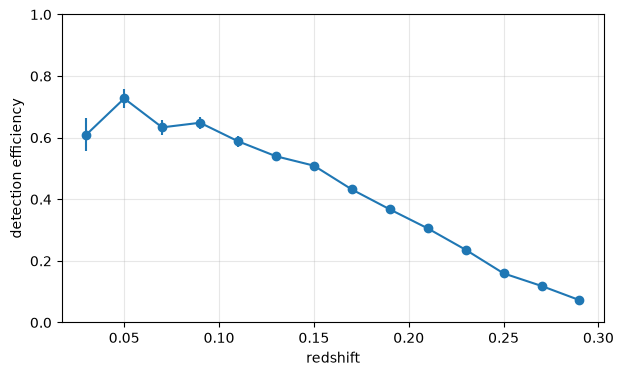

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(zmid, eff, yerr=eff_err, marker="o", color="C0")
ax.set_xlabel("redshift")
ax.set_ylabel("detection efficiency")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3);

Two effects are visible:

- At low redshift the efficiency plateaus around 60-70%, not 100%. These supernovae are bright enough, but some
  exploded in regions ZTF did not observe often enough during the window (gaps in the cadence, bad weather,
  fields close to the edge of the footprint), so they lack the required number of detections.
- Above $z \sim 0.1$ the efficiency drops steadily: distant supernovae are fainter and their peak gets closer to the
  ZTF limiting magnitude ($\sim 20.5$ mag), so fewer points reach $S/N \geq 5$.

## Malmquist bias

Close to the detection limit, the supernovae that *are* detected are preferentially the intrinsically brightest ones.
This is the Malmquist bias. For SNe Ia, bright means high stretch (`x1 > 0`) and blue color (`c < 0`), so the detected
sample becomes increasingly biased toward these values at high redshift, while the true population does not change with
redshift. Let us compare the mean `x1`, `c` and `magobs` of all and detected supernovae in each redshift bin.

In [10]:
keys = ["x1", "c", "magobs"]
mean_all = grouped[keys].mean()
mean_det = data[data["detected"]].groupby("zbin", observed=False)[keys].mean()
mean_det.head()

,x1,c,magobs
zbin,,,
"(0.02, 0.04]",-0.155400,0.095060,16.818201
"(0.04, 0.06]",-0.191563,0.062094,17.772694
"(0.06, 0.08]",-0.160248,0.062521,18.487299
"(0.08, 0.1]",-0.174783,0.056743,19.050787
"(0.1, 0.12]",-0.230426,0.063942,19.539244


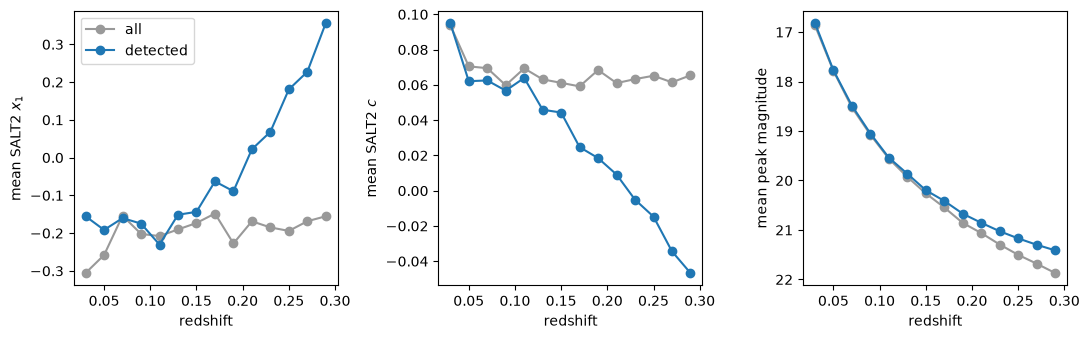

In [11]:
labels = {"x1": "mean SALT2 $x_1$", "c": "mean SALT2 $c$", "magobs": "mean peak magnitude"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharex=True)
for ax, key in zip(axes, keys):
    ax.plot(zmid, mean_all[key], marker="o", color="0.6", label="all")
    ax.plot(zmid, mean_det[key], marker="o", color="C0", label="detected")
    ax.set_xlabel("redshift")
    ax.set_ylabel(labels[key])
axes[2].invert_yaxis()  # brighter (smaller magnitude) at the top
axes[0].legend()
fig.tight_layout();

At low redshift the detected and true populations agree. As the efficiency drops, the detected supernovae drift toward
larger stretch and bluer color, and they are brighter than the average supernova at the same redshift.
If not accounted for, this bias propagates into the distances measured from the detected sample, which is why
cosmological analyses rely on simulations like this one to correct for it.

## Hubble diagram of detected and missed supernovae

Finally, let us look at the true peak magnitude of every simulated supernova as a function of redshift, colored by
whether it was detected. The dashed line shows the expected magnitude of a standard SN Ia ($M = -19.3$) in the
simulation cosmology (`snia.cosmology`).

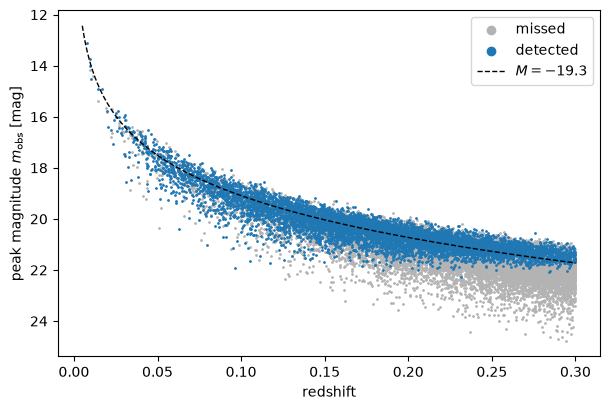

In [12]:
zz = np.linspace(0.005, 0.3, 200)
mag_standard = -19.3 + snia.cosmology.distmod(zz).value

fig, ax = plt.subplots(figsize=(7, 4.5))
missed, detected = data[~data["detected"]], data[data["detected"]]
ax.scatter(missed["z"], missed["magobs"], s=1, color="0.7", label="missed", rasterized=True)
ax.scatter(detected["z"], detected["magobs"], s=1, color="C0", label="detected", rasterized=True)
ax.plot(zz, mag_standard, color="k", ls="--", lw=1, label="$M=-19.3$")
ax.set_xlabel("redshift")
ax.set_ylabel("peak magnitude $m_\\mathrm{obs}$ [mag]")
ax.invert_yaxis()
ax.legend(markerscale=6, loc="upper right");

Missed supernovae are found at all redshifts (cadence and coverage losses), but beyond $z \sim 0.15$ the detected ones
sit increasingly above the dashed line: only the brightest part of the population survives, and the faint side of the
Hubble diagram empties out.

## Going further: a spectroscopic selection

Detected supernovae must usually be confirmed by a spectrum, and spectroscopic follow-up is itself magnitude limited.
The `skysurvey.selection` module helps draw such a probabilistic selection: `draw_from_selection` evaluates a
probability function on a column and draws the selected sample redshift bin by redshift bin. Here we use a smooth
completeness that falls to 50% at $m_\mathrm{obs} = 18.5$ mag, similar to ZTF's spectroscopic follow-up.

In [13]:
from scipy.special import expit
from skysurvey import selection

def spectro_completeness(mag, mag50=18.5, steepness=4):
    return 1 - expit((mag - mag50) * steepness)

typed = selection.draw_from_selection(data[data["detected"]], spectro_completeness, key="magobs")
print(f"{len(typed):,} SNe Ia spectroscopically typed out of {data['detected'].sum():,} detected")

426 SNe Ia spectroscopically typed out of 7,107 detected


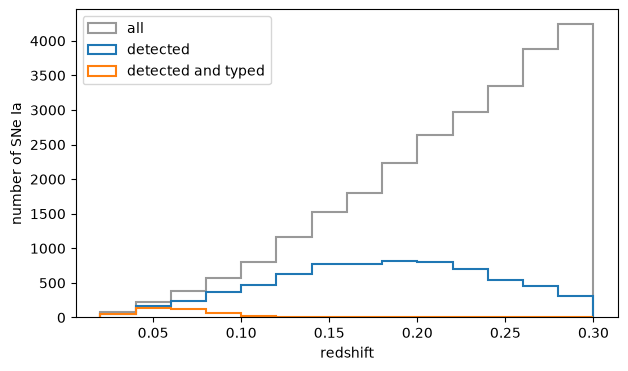

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
prop = dict(bins=zbins, histtype="step", lw=1.5)
ax.hist(data["z"], color="0.6", label="all", **prop)
ax.hist(data.loc[data["detected"], "z"], color="C0", label="detected", **prop)
ax.hist(typed["z"], color="C1", label="detected and typed", **prop)
ax.set_xlabel("redshift")
ax.set_ylabel("number of SNe Ia")
ax.legend();

## Next steps

- [ZTF volume-limited rates](../analysisexamples/ztf_volumelimited_rates.ipynb): a full ZTF DR2-like simulation, including the DR2 lightcurve cuts.
- [Change the rate](../howto/change_rate.ipynb) of a target to explore other populations.
- [Targets and sky area](../howto/target_and_skyarea.ipynb): more on restricting a draw to a survey footprint.
- [Add Milky Way extinction](../howto/add_mwebv.ipynb), an extra source of selection near the Galactic plane.